# Neuro-Symbolic AI for Skincare Recommendation System
**Graduation Project**

**Developed by:**
- Luna AlShiekh
- Ali Saqour

**Abstract:**
This project presents an advanced skincare recommendation system integrating Knowledge Graphs (KG), Graph Attention Networks (GAT), and Large Language Models (LLMs). The architecture ensures medical safety constraints via deterministic graph rules while utilizing graph representation learning and LLM agents for precise, context-aware user interactions.

## 1. Environment Setup and Dependencies
Installing the required libraries including PyTorch Geometric, SentenceTransformers, and LangGraph.

In [8]:
import os
import re
import pandas as pd
import networkx as nx
import torch

# Dynamically retrieve PyTorch and CUDA versions to ensure compatible PyG installation
torch_version = torch.__version__.split('+')[0]
if torch.version.cuda:
    cuda_version = torch.version.cuda.replace('.', '')
    wheel_url = f"https://data.pyg.org/whl/torch-{torch_version}+cu{cuda_version}.html"
else:
    wheel_url = f"https://data.pyg.org/whl/torch-{torch_version}+cpu.html"

print("Installing dependencies...")
os.system(f"pip install -q pyg_lib torch-scatter torch-sparse torch-cluster -f {wheel_url}")
os.system("pip install -q torch-geometric==2.5.3")
os.system("pip install -q pandas networkx sentence-transformers langgraph langchain-google-genai pydantic requests")
print("Installation complete.")

Installing dependencies...
Installation complete.


In [11]:
import os
import pandas as pd

# البحث عن جميع ملفات الإكسل في المجلد وتحويلها تلقائياً
for file in os.listdir('.'):
    if file.endswith('.xlsx'):
        print(f"جاري تحويل: {file} ...")
        df = pd.read_excel(file)

        # حفظ الملف بصيغة csv بالاسم المطابق تماماً
        csv_name = file.replace('.xlsx', '.csv')
        df.to_csv(csv_name, index=False)

        # حفظ نسخة أخرى بدون مسافات إضافية احتياطاً
        clean_name = file.replace('.xlsx', '').strip() + '.csv'
        df.to_csv(clean_name, index=False)

print("\n✅ تم تحويل جميع ملفات الإكسل إلى CSV بنجاح!")
print("ملفات الـ CSV المتوفرة الآن:")
for f in os.listdir('.'):
    if f.endswith('.csv'):
        print(f"📄 {f}")

جاري تحويل: جدول المنتجات حديث.xlsx ...
جاري تحويل: جدول قواعد.xlsx ...
جاري تحويل: جدول انواع البشرة و حالاتها.xlsx ...
جاري تحويل: جدول المكونات.xlsx ...

✅ تم تحويل جميع ملفات الإكسل إلى CSV بنجاح!
ملفات الـ CSV المتوفرة الآن:
📄 جدول قواعد.csv
📄 جدول المكونات.csv
📄 جدول انواع البشرة و حالاتها.csv
📄 جدول المنتجات حديث.csv


## 2. Knowledge Graph Construction
Defining the deterministic constraints and relationships using a Directed Graph. This module serves as a safety filter to prevent recommending products with contraindicated ingredients.

In [12]:
class SkincareKnowledgeGraph:
    def __init__(self):
        self.G = nx.DiGraph()

    def train_graph(self, skin_df, rules_df, ingredients_df, products_df):
        # 1. Integrate Skin Types
        for _, row in skin_df.iterrows():
            skin_type = str(row['SkinType (نوع البشرة)وحالاتها']).strip()
            desc = str(row['Description (الوصف)']).strip()
            chars = str(row['Characteristics (الخصائص والمميزات)']).strip()
            self.G.add_node(skin_type, type="SkinType", description=desc, characteristics=chars)

        # 2. Integrate Treatment Rules
        for _, row in rules_df.iterrows():
            problems_raw = str(row['And_Problem_Is (والمشكلة هي)']).split(',')
            raw_text = str(row['Then_Recommend_Ingredient (إذن، المكون الموصى به)'])
            clean_text = re.sub(r'\(.*?\)', '', raw_text)
            ingredients_raw = clean_text.split(',')

            for prob in problems_raw:
                prob = prob.strip()
                for ing in ingredients_raw:
                    ing_clean = ing.strip()
                    if ing_clean:
                        self.G.add_edge(ing_clean, prob, relation="TREATS_BY_RULE")

                        # Add synonymous ingredients for robust linking
                        if "Retinoids" in ing_clean:
                            self.G.add_edge("Retinol", prob, relation="TREATS_BY_RULE")
                            self.G.add_edge("Adapalene", prob, relation="TREATS_BY_RULE")
                            self.G.add_edge("Retinal", prob, relation="TREATS_BY_RULE")

        # 3. Integrate Ingredients
        for _, row in ingredients_df.iterrows():
            ing_name_raw = str(row['اسم المكون (Ingredient Name)']).strip()
            match = re.search(r'\((.*?)\)', ing_name_raw)
            ing_name = match.group(1).strip() if match else ing_name_raw

            function = str(row['الوظيفة (Function)']).strip()
            good_for_probs = str(row['مناسب لمشكلة (Good For Problem)']).split('،')

            self.G.add_node(ing_name, type="Ingredient", function=function)

            for prob in good_for_probs:
                prob = prob.strip()
                self.G.add_edge(ing_name, prob, relation="TREATS_BY_INGREDIENT")

        # 4. Strict Medical Constraints (Contraindications)
        sensitive_avoids = [
            'Glycolic Acid', 'Salicylic Acid', 'Lactic Acid',
            'AHA', 'BHA', 'Benzoyl Peroxide', 'High-strength Retinol'
        ]
        for acid in sensitive_avoids:
            self.G.add_edge("Sensitive (الحساسة)", acid, relation="AVOIDS")
            self.G.add_edge("Sensitive", acid, relation="AVOIDS")
            self.G.add_edge("Rosacea", acid, relation="AVOIDS")
            self.G.add_edge("Eczema", acid, relation="AVOIDS")

        # 5. Integrate Products
        for _, row in products_df.iterrows():
            product_name = str(row['ProductName']).strip()
            category = str(row['Category']).strip()
            key_ingredients = str(row['KeyIngredients']).split(',')
            suitable_skins = str(row['SuitableForSkinType']).split(',')

            self.G.add_node(product_name, type="Product", category=category)

            for ing in key_ingredients:
                ing_clean = re.sub(r'\(.*?\)', '', ing).strip()
                if ing_clean:
                    self.G.add_edge(product_name, ing_clean, relation="CONTAINS")

            for skin in suitable_skins:
                skin = skin.strip()
                self.G.add_edge(product_name, skin, relation="SUITABLE_FOR")

        print(f"Knowledge Graph initialized: {self.G.number_of_nodes()} nodes, {self.G.number_of_edges()} edges.")

    def call_knowledge_graph(self, skin_type, active_problems, category_filter=None):
        if category_filter is None:
            category_filter = ["Cleanser", "Toner", "Serum", "Treatment", "Moisturizer", "Essence", "Mask", "Sunscreen"]

        avoid_ingredients = set()
        recommended_ingredients = set()

        skin_en = re.sub(r'\(.*?\)', '', skin_type).strip()

        # Retrieve contraindicated ingredients
        if skin_type in self.G:
            for neighbor in self.G.neighbors(skin_type):
                if self.G[skin_type][neighbor]['relation'] == 'AVOIDS':
                    avoid_ingredients.add(neighbor)

        if skin_en in self.G and skin_en != skin_type:
            for neighbor in self.G.neighbors(skin_en):
                if self.G[skin_en][neighbor]['relation'] == 'AVOIDS':
                    avoid_ingredients.add(neighbor)

        for prob in active_problems:
            if prob in self.G:
                for neighbor in self.G.neighbors(prob):
                    if self.G[prob][neighbor]['relation'] == 'AVOIDS':
                        avoid_ingredients.add(neighbor)

        # Retrieve therapeutic ingredients
        for prob in active_problems:
            for node in self.G.nodes():
                if self.G.has_edge(node, prob):
                    rel = self.G[node][prob]['relation']
                    if rel in ['TREATS_BY_RULE', 'TREATS_BY_INGREDIENT']:
                        if node not in avoid_ingredients:
                            recommended_ingredients.add(node)

        # Filter 100% safe products
        safe_products = []
        for product in self.G.nodes():
            if self.G.nodes[product].get('type') == 'Product':
                prod_category = self.G.nodes[product].get('category', '')

                if not any(cat.lower() in prod_category.lower() for cat in category_filter):
                    continue

                is_suitable = False
                contains_active = False
                contains_avoided = False

                for n in self.G.neighbors(product):
                    if self.G[product][n]['relation'] == 'SUITABLE_FOR':
                        if skin_en.lower() in n.lower() or 'all types' in n.lower():
                            is_suitable = True
                            break

                if is_suitable:
                    for n in self.G.neighbors(product):
                        if self.G[product][n]['relation'] == 'CONTAINS':
                            if any(banned.lower() in n.lower() for banned in avoid_ingredients):
                                contains_avoided = True
                            if any(rec.lower() in n.lower() for rec in recommended_ingredients):
                                contains_active = True

                    if contains_active and not contains_avoided:
                        safe_products.append(product)

        return {
            "Skin_Type_Detected": skin_type,
            "Problems_Detected": active_problems,
            "Avoided_Ingredients": list(avoid_ingredients),
            "Safe_Ingredients": list(recommended_ingredients),
            "Recommended_Products": safe_products[:5]
        }

## 3. Data Loading and KG Initialization
Ensure the CSV dataset files are placed in the correct working directory before executing this block.

In [13]:
# Note: Keep the exact file names you used in your dataset.
try:
    skin_df = pd.read_csv('جدول انواع البشرة و حالاتها.csv', encoding='utf-8-sig')
    rules_df = pd.read_csv('جدول قواعد.csv', encoding='utf-8-sig')
    ingredients_df = pd.read_csv('جدول المكونات.csv', encoding='utf-8-sig')
    products_df = pd.read_csv('جدول المنتجات حديث.csv', encoding='utf-8-sig')

    global kg_tool
    kg_tool = SkincareKnowledgeGraph()
    kg_tool.train_graph(skin_df, rules_df, ingredients_df, products_df)

except Exception as e:
    print(f"Error loading datasets: {e}")
    print("Please ensure the CSV files are uploaded to the current directory.")

Knowledge Graph initialized: 961 nodes, 1837 edges.


In [14]:
import pickle

# حفظ الـ Knowledge Graph
with open('kg_graph.pkl', 'wb') as f:
    pickle.dump(kg_tool.G, f)
print("✅ تم حفظ Knowledge Graph بنجاح!")

✅ تم حفظ Knowledge Graph بنجاح!


In [15]:
!pip install pyvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 116.5 MB/s eta 0:00:00


In [16]:
import pickle
from pyvis.network import Network

print("جاري بناء المحاكاة الكاملة للشبكة... ⏳")

# 1. تحميل الجراف
with open('kg_graph.pkl', 'rb') as f:
    G = pickle.load(f)

# 2. إنشاء الشبكة التفاعلية (بحجم الشاشة بالكامل)
net = Network(height="100vh", width="100%", bgcolor="#0e1117", font_color="white")

# 3. تلوين العقد بالكامل
for node, data in G.nodes(data=True):
    n_type = data.get('type', 'Unknown')

    if n_type == 'Product':
        color, size = '#FFD700', 30  # المنتجات ذهبية
    elif n_type == 'Ingredient':
        color, size = '#00FA9A', 20  # المكونات خضراء
    elif n_type == 'SkinType':
        color, size = '#0078D7', 45  # أنواع البشرة زرقاء
    else:
        color, size = '#FF4B4B', 35  # المشاكل حمراء

    net.add_node(
        node,
        label=str(node),
        title=f"{n_type}: {node}",
        color=color,
        size=size,
        font={'color': 'white', 'size': 12, 'face': 'Tajawal'}
    )

# 4. رسم كل الروابط (Edges)
for source, target, data in G.edges(data=True):
    net.add_edge(source, target, color="rgba(255, 255, 255, 0.2)", width=1)

# 5. إعدادات الفيزياء + تفعيل لوحة التحكم (مدمجة هنا لتفادي الخطأ)
net.set_options("""
var options = {
  "configure": {
    "enabled": true,
    "filter": ["physics"]
  },
  "physics": {
    "solver": "forceAtlas2Based",
    "forceAtlas2Based": {
      "gravitationalConstant": -150,
      "centralGravity": 0.02,
      "springLength": 120,
      "springConstant": 0.05,
      "damping": 0.6
    },
    "maxVelocity": 50,
    "minVelocity": 0.5,
    "stabilization": {
      "enabled": true,
      "iterations": 150,
      "updateInterval": 25,
      "onlyDynamicEdges": false,
      "fit": true
    }
  }
}
""")

# 6. حفظ المحاكاة
file_name = "Full_Simulation.html"
net.save_graph(file_name)

print("✅ تم بناء المحاكاة بنجاح وبدون أخطاء!")
print(f"يرجى الذهاب إلى مجلد الملفات (على يسار الشاشة) وتنزيل ملف: {file_name}")

جاري بناء المحاكاة الكاملة للشبكة... ⏳
✅ تم بناء المحاكاة بنجاح وبدون أخطاء!
يرجى الذهاب إلى مجلد الملفات (على يسار الشاشة) وتنزيل ملف: Full_Simulation.html


## 4. Graph Representation Learning (GAT & Embeddings)
In this section, we utilize `SentenceTransformers` to generate dense vector representations (embeddings) for textual node attributes. We also introduce a `Type-Aware Embedding` layer to distinguish between different entities (Products, Ingredients, Skin Types). Finally, a Graph Attention Network (GAT) is defined to capture the multi-hop relational dependencies.

In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from sentence_transformers import SentenceTransformer
import numpy as np

print("Loading SentenceTransformer model for text embeddings...")
embedding_model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
print("Model loaded successfully.")

NODE_TYPES = {
    "SkinType":   0,
    "Ingredient": 1,
    "Product":    2,
    "Problem":    3,
    "Unknown":    4,
}
TYPE_EMB_DIM = 16

def prepare_graph_data(G):
    print(f"Preparing graph data: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges.")

    node_list = list(G.nodes())
    node_to_id = {n: i for i, n in enumerate(node_list)}
    id_to_node = {i: n for n, i in node_to_id.items()}
    num_nodes = len(node_list)

    node_texts = []
    node_type_ids = []

    for node in node_list:
        attrs = G.nodes[node]
        node_type = attrs.get('type', 'Unknown')
        type_id = NODE_TYPES.get(node_type, 4)
        node_type_ids.append(type_id)

        if node_type == "Product":
            category = attrs.get('category', '')
            desc = f"skincare product {node} category {category}"
        elif node_type == "Ingredient":
            function = attrs.get('function', '')
            desc = f"ingredient {node} function {function}"
        elif node_type == "SkinType":
            characteristics = attrs.get('characteristics', '')
            description = attrs.get('description', '')
            desc = f"skin type {node} {description} {characteristics}"
        else:
            desc = f"{node_type} {node}"

        node_texts.append(desc)

    # Text Embeddings (384 dimensions)
    text_emb_array = embedding_model.encode(node_texts, show_progress_bar=False)
    text_emb = torch.tensor(text_emb_array, dtype=torch.float)

    # Type Embeddings (16 dimensions)
    type_emb_layer = nn.Embedding(len(NODE_TYPES), TYPE_EMB_DIM)
    type_ids_tensor = torch.tensor(node_type_ids, dtype=torch.long)
    type_emb = type_emb_layer(type_ids_tensor).detach()

    # Concatenate features (Total: 400 dimensions)
    x = torch.cat([text_emb, type_emb], dim=1)

    # Bidirectional edges
    edges = list(G.edges())
    src = [node_to_id[s] for s, _ in edges]
    dst = [node_to_id[d] for _, d in edges]
    edge_index = torch.tensor([src + dst, dst + src], dtype=torch.long)

    # Train / Validation Split (80% Train, 20% Validation)
    indices = np.arange(num_nodes)
    np.random.shuffle(indices)
    split_idx = int(num_nodes * 0.8)

    train_mask = torch.zeros(num_nodes, dtype=torch.bool)
    val_mask = torch.zeros(num_nodes, dtype=torch.bool)

    train_mask[indices[:split_idx]] = True
    val_mask[indices[split_idx:]] = True

    graph_data = Data(x=x, edge_index=edge_index)
    graph_data.node_type_ids = type_ids_tensor
    graph_data.train_mask = train_mask
    graph_data.val_mask = val_mask

    return graph_data, node_to_id, id_to_node, num_nodes, node_type_ids

Loading SentenceTransformer model for text embeddings...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded successfully.


## 5. Model Architecture & Loss Function
We implement a Graph Attention Network (GAT) to learn dynamic edge importance. A custom `type_aware_contrastive_loss` is utilized to ensure that the model learns distinct representations by drawing negative samples from the same node category (e.g., contrasting a product with another product rather than a random ingredient).

In [18]:
class SkincareGAT(nn.Module):
    def __init__(self, in_channels, hidden_channels=128, out_channels=64, heads=8, dropout=0.3):
        super(SkincareGAT, self).__init__()
        self.dropout = dropout

        # Multi-head Attention layer
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout, concat=True)
        # Output layer (Single head)
        self.conv2 = GATConv(hidden_channels * heads, out_channels, heads=1, dropout=dropout, concat=False)

        self.bn1 = nn.BatchNorm1d(hidden_channels * heads)
        self.bn2 = nn.BatchNorm1d(out_channels)

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.elu(x)

        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        x = self.bn2(x)

        return x

    def get_embeddings(self, graph_data):
        self.eval()
        with torch.no_grad():
            return self.forward(graph_data.x, graph_data.edge_index)

def type_aware_contrastive_loss(embeddings, edge_index, node_type_ids, mask=None, margin=1.0):
    src_nodes = edge_index[0]
    dst_nodes = edge_index[1]

    # Filter edges based on the provided mask (Train or Validation)
    if mask is not None:
        valid_edges = mask[src_nodes]
        src_nodes = src_nodes[valid_edges]
        dst_nodes = dst_nodes[valid_edges]
        if len(src_nodes) == 0:
            return torch.tensor(0.0, requires_grad=True), 0.0

    pos_src = embeddings[src_nodes]
    pos_dst = embeddings[dst_nodes]
    pos_sim = F.cosine_similarity(pos_src, pos_dst)
    pos_loss = (1 - pos_sim).mean()

    # Draw negative samples from the same node type
    src_types = node_type_ids[src_nodes]
    neg_indices = []

    for t in src_types:
        same_type = (node_type_ids == t).nonzero(as_tuple=True)[0]
        rand_pick = same_type[torch.randint(len(same_type), (1,))]
        neg_indices.append(rand_pick.item())

    neg_idx = torch.tensor(neg_indices, dtype=torch.long)
    neg_dst = embeddings[neg_idx]
    neg_sim = F.cosine_similarity(pos_src, neg_dst)
    neg_loss = F.relu(margin - (1 - neg_sim)).mean()

    total_loss = pos_loss + neg_loss

    # Calculate Contrastive Accuracy: How often is Positive Similarity > Negative Similarity?
    accuracy = (pos_sim > neg_sim).float().mean().item()

    return total_loss, accuracy

## 6. Training Pipeline and Multi-hop Recommendation Engine
This module handles the training of the GAT model. After generating node embeddings, a multi-hop scoring algorithm computes a weighted similarity score based on both direct relevance (Product ↔ Problem) and indirect therapeutic bridges (Product ↔ Ingredient ↔ Problem).

In [19]:
import matplotlib.pyplot as plt

def train_gat(graph_data, num_nodes, epochs=500, lr=0.005, patience=100):
    in_channels = graph_data.num_node_features
    model = SkincareGAT(
        in_channels=in_channels,
        hidden_channels=64,
        out_channels=64,
        heads=8,
        dropout=0.3
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=20)
    node_type_ids = graph_data.node_type_ids

    best_val_loss = float('inf')
    best_state = None
    no_improve = 0

    # Dictionary to track metrics for plotting
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': []
    }

    print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>10} | {'Val Loss':>10} | {'Val Acc':>10}")
    print("-" * 65)

    for epoch in range(epochs + 1):
        # Training Phase
        model.train()
        optimizer.zero_grad()
        out = model(graph_data.x, graph_data.edge_index)

        train_loss, train_acc = type_aware_contrastive_loss(
            out, graph_data.edge_index, node_type_ids, mask=graph_data.train_mask
        )

        train_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step(train_loss)

        # Validation Phase
        model.eval()
        with torch.no_grad():
            val_out = model(graph_data.x, graph_data.edge_index)
            val_loss, val_acc = type_aware_contrastive_loss(
                val_out, graph_data.edge_index, node_type_ids, mask=graph_data.val_mask
            )

        # Record history
        history['train_loss'].append(train_loss.item())
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss.item())
        history['val_acc'].append(val_acc)

        if val_loss.item() < best_val_loss:
            best_val_loss = val_loss.item()
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1

        if epoch % 20 == 0:
            print(f"{epoch:5d} | {train_loss.item():10.4f} | {train_acc:10.4f} | {val_loss.item():10.4f} | {val_acc:10.4f}")

        if no_improve >= patience:
            print(f"\nEarly stopping triggered at Epoch {epoch} (Best epoch was {epoch - patience})")
            break

    model.load_state_dict(best_state)
    print(f"\nTraining completed. Best Validation Loss: {best_val_loss:.4f}")
    return model, history

def plot_training_curves(history):
    epochs_range = range(len(history['train_loss']))

    plt.figure(figsize=(14, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='blue', linewidth=2)
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss', color='red', linewidth=2, linestyle='--')
    plt.title('Type-Aware Contrastive Loss over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='blue', linewidth=2)
    plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', color='red', linewidth=2, linestyle='--')
    plt.title('Contrastive Accuracy over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)

    plt.tight_layout()
    plt.show()

def compute_multihop_score(product_name, problem_name, skin_type, embeddings, node_to_id, kg_tool, alpha=0.4):
    G = kg_tool.G
    prob_emb = embeddings[node_to_id[problem_name]]
    product_emb = embeddings[node_to_id[product_name]]

    # Direct Similarity Score
    direct_score = F.cosine_similarity(prob_emb.unsqueeze(0), product_emb.unsqueeze(0)).item()

    # Ingredient Bridge Score
    bridge_scores = []
    for neighbor in G.neighbors(product_name):
        rel = G[product_name][neighbor].get('relation', '')
        if rel == 'CONTAINS' and neighbor in node_to_id:
            ing_emb = embeddings[node_to_id[neighbor]]
            prob_ing_sim = F.cosine_similarity(prob_emb.unsqueeze(0), ing_emb.unsqueeze(0)).item()
            bridge_scores.append(prob_ing_sim)

    bridge_score = max(bridge_scores) if bridge_scores else 0.0

    # Final Weighted Score
    final_score = alpha * direct_score + (1 - alpha) * bridge_score

    return {
        "final_score": round(final_score, 4),
        "direct_score": round(direct_score, 4),
        "bridge_score": round(bridge_score, 4),
        "num_ingredients": len(bridge_scores),
    }

def gnn_recommend_pro(problem_name, skin_type, graph_data, gat_model, node_to_id, id_to_node, kg_tool, top_k=5, diverse=True, category_filter=None):
    # Phase A: Deterministic Safety Filter
    safe_result = kg_tool.call_knowledge_graph(
        skin_type=skin_type,
        active_problems=[problem_name],
        category_filter=category_filter
    )
    safe_products = set(safe_result["Recommended_Products"])

    if not safe_products:
        return []

    # Phase B: GAT + Multi-hop Ranking
    if problem_name not in node_to_id:
        return []

    embeddings = gat_model.get_embeddings(graph_data)
    scored_products = []

    for product_name in safe_products:
        if product_name not in node_to_id:
            continue

        scores = compute_multihop_score(
            product_name=product_name,
            problem_name=problem_name,
            skin_type=skin_type,
            embeddings=embeddings,
            node_to_id=node_to_id,
            kg_tool=kg_tool,
            alpha=0.4
        )

        category = kg_tool.G.nodes[product_name].get('category', 'N/A')
        scored_products.append({
            "product": product_name,
            "category": category,
            "final_score": scores["final_score"],
            "direct_score": scores["direct_score"],
            "bridge_score": scores["bridge_score"],
            "num_ingredients": scores["num_ingredients"],
        })

    scored_products.sort(key=lambda x: x["final_score"], reverse=True)

    # Phase C: Category Diversity Filter
    if diverse:
        seen_categories = set()
        diverse_list = []
        leftover = []

        for p in scored_products:
            if p["category"] not in seen_categories:
                diverse_list.append(p)
                seen_categories.add(p["category"])
            else:
                leftover.append(p)

        final_list = (diverse_list + leftover)[:top_k]
    else:
        final_list = scored_products[:top_k]

    for i, p in enumerate(final_list):
        p["rank"] = i + 1

    return final_list

def run_pro_system(kg_tool):
    graph_data, node_to_id, id_to_node, num_nodes, node_type_ids = prepare_graph_data(kg_tool.G)
    gat_model, history = train_gat(graph_data, num_nodes, epochs=500, lr=0.005, patience=100)
    return gat_model, graph_data, node_to_id, id_to_node, history

## 7. Model Execution
Initializing the graph embedding vectors and running the training loop. This cell establishes the global models required for the LLM agents to perform intelligent retrieval.

Preparing graph data: 961 nodes, 1837 edges.
Epoch | Train Loss |  Train Acc |   Val Loss |    Val Acc
-----------------------------------------------------------------
    0 |     1.1029 |     0.4292 |     1.0705 |     0.4449
   20 |     0.6175 |     0.8549 |     0.6054 |     0.8449
   40 |     0.5043 |     0.9088 |     0.4874 |     0.9026
   60 |     0.4676 |     0.9171 |     0.4435 |     0.9410
   80 |     0.4477 |     0.9160 |     0.4577 |     0.9051
  100 |     0.4298 |     0.9281 |     0.4283 |     0.9269
  120 |     0.4241 |     0.9330 |     0.4222 |     0.9449
  140 |     0.4276 |     0.9281 |     0.4209 |     0.9397
  160 |     0.4121 |     0.9305 |     0.4276 |     0.9231
  180 |     0.4086 |     0.9340 |     0.4177 |     0.9244
  200 |     0.4010 |     0.9416 |     0.4176 |     0.9256
  220 |     0.3998 |     0.9416 |     0.4254 |     0.9244
  240 |     0.3979 |     0.9406 |     0.4150 |     0.9205
  260 |     0.3985 |     0.9423 |     0.4126 |     0.9436
  280 |     0.4003 

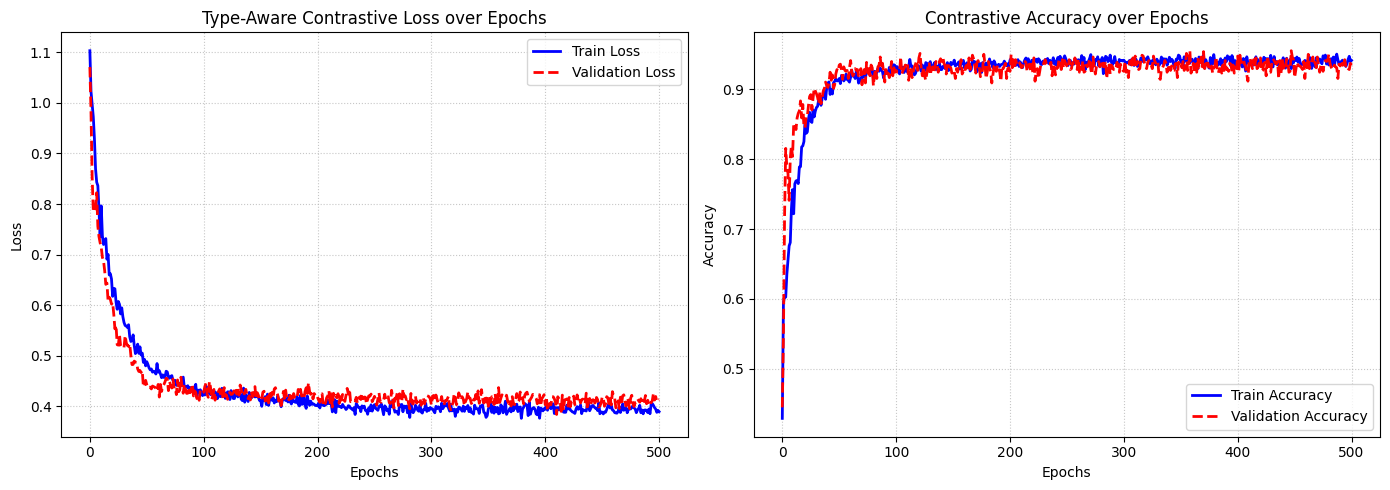

In [20]:
# Execute graph preparation, model training, and generate training curves
if 'kg_tool' in globals():
    gat_model, graph_data, node_to_id, id_to_node, history = run_pro_system(kg_tool)
    plot_training_curves(history)
else:
    print("Error: kg_tool is not initialized. Please run the Knowledge Graph section first.")

In [21]:
import torch

# حفظ الـ Graph Data (والتي تحتوي على الـ Embeddings)
torch.save(graph_data, 'graph_data.pt')

# حفظ قواميس تحويل الأسماء إلى أرقام والعكس
with open('mappings.pkl', 'wb') as f:
    pickle.dump({'node_to_id': node_to_id, 'id_to_node': id_to_node}, f)

print("✅ تم حفظ مصفوفات البيانات والقواميس بنجاح!")

✅ تم حفظ مصفوفات البيانات والقواميس بنجاح!


In [22]:
# حفظ أوزان نموذج GAT المدرب
torch.save(gat_model.state_dict(), 'gat_model_weights.pth')
print("✅ تم حفظ نموذج GAT بنجاح!")

✅ تم حفظ نموذج GAT بنجاح!


## 8. LLM Agents & LangGraph Integration
Integrating Large Language Models (LLMs) to serve as the conversational interface. The system employs a multi-agent architecture using `LangGraph`:
1. **Triage Agent:** Parses user input in Arabic to dynamically update the state.
2. **Engine Agent:** Invokes the trained GAT model.
3. **Pharmacist Agent:** Translates the outputs into a professional medical consultation in Arabic.

In [23]:
import os
import json
import re
from getpass import getpass
from typing import TypedDict, List
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate

# Securely input the Google API Key
print("Please enter your Google Gemini API Key:")
os.environ["GOOGLE_API_KEY"] = getpass("API Key: ")

# Initialize the LLM
llm = ChatGoogleGenerativeAI(model="gemini-3-flash-preview", temperature=0)
print("LLM Initialized Successfully.")

Please enter your Google Gemini API Key:
API Key: ··········
LLM Initialized Successfully.


In [24]:
class SkincareState(TypedDict):
    user_message: str
    skin_type: str
    active_problems: List[str]
    raw_recommendations: List[dict]
    final_response: str

def triage_agent(state: SkincareState):
    current_skin = state.get('skin_type', 'Unknown')
    probs = state.get('active_problems', ['Unknown'])
    current_prob = probs[0] if probs else 'Unknown'

    prompt = ChatPromptTemplate.from_messages([
        ("system", """
        أنت طبيب جلدية ذكي.
        هذه هي المعلومات المحفوظة مسبقاً عن المريض:
        - نوع البشرة المعروف حالياً: {current_skin}
        - المشكلة المعروفة حالياً: {current_prob}

        المطلوب:
        استخرج أي تحديثات من رسالة المريض الجديدة وادمجها مع المعلومات القديمة لتحديد:
        1. المشكلة (من: "Acne (General)", "Dehydrated Skin", "Hyperpigmentation", "Wrinkles", "Rosacea").
        2. نوع البشرة (من: "Sensitive (الحساسة)", "Dry (الجافة)", "Oily (الدهنية)", "Combination (المختلطة)", "Normal (العادية)").

        قواعد صارمة:
        - إذا ذكر المريض معلومة جديدة، قم بتحديثها.
        - إذا لم يذكر معلومة جديدة (مثلاً قال "دهنية" فقط)، حافظ على المشكلة القديمة كما هي!
        - لا تخمن أبداً.

        أعد JSON فقط: {{"skin_type": "...", "problem": "..."}}
        """),
        ("user", "{message}")
    ])

    response = (prompt | llm).invoke({
        "message": state["user_message"],
        "current_skin": current_skin,
        "current_prob": current_prob
    })

    text_content = response.content[0].get("text", "") if isinstance(response.content, list) else str(response.content)

    # Robust JSON extraction to prevent parsing errors
    json_match = re.search(r'\{.*?\}', text_content, re.DOTALL)
    clean_json = json_match.group(0) if json_match else "{}"

    try:
        extracted_data = json.loads(clean_json)
    except:
        extracted_data = {"skin_type": current_skin, "problem": current_prob}

    return {
        "skin_type": extracted_data.get('skin_type', current_skin),
        "active_problems": [extracted_data.get('problem', current_prob)]
    }

def engine_agent(state: SkincareState):
    problem = state['active_problems'][0]
    skin = state['skin_type']

    results = gnn_recommend_pro(
        problem_name=problem,
        skin_type=skin,
        graph_data=graph_data,
        gat_model=gat_model,
        node_to_id=node_to_id,
        id_to_node=id_to_node,
        kg_tool=kg_tool,
        top_k=3,
        diverse=True
    )

    if results:
        print(f"\n[{'-'*50}]")
        print(f"[Backend GAT Engine Evaluation]")
        for r in results:
            print(f"Rank {r['rank']}: {r['product']} | Category: {r['category']}")
            print(f"Final Score: {r['final_score']:.4f} | Direct: {r['direct_score']:.4f} | Bridge: {r['bridge_score']:.4f}")
        print(f"[{'-'*50}]\n")

    return {"raw_recommendations": results}

def pharmacist_agent(state: SkincareState):
    skin = state.get('skin_type', 'Unknown')
    probs = state.get('active_problems', ['Unknown'])
    prob = probs[0] if probs else 'Unknown'
    user_message = state.get('user_message', '')

    # Hardcoded deterministic responses for missing data (No Emojis)
    if skin == "Unknown" and prob == "Unknown":
        return {"final_response": "أهلاً بك. يسعدني جداً مساعدتك. للحصول على أفضل روتين طبي آمن لبشرتك، يرجى إخباري: ما هي المشكلة التي تعاني منها حالياً؟ وما هو نوع بشرتك؟"}

    elif skin == "Unknown" and prob != "Unknown":
        return {"final_response": f"أهلاً بك. لكي أتمكن من مساعدتك في علاج مشكلة {prob} بطريقة آمنة، يجب أن أعرف أولاً نوع بشرتك (دهنية، جافة، مختلطة، حساسة، أم عادية؟). بانتظار ردك."}

    elif skin != "Unknown" and prob == "Unknown":
        return {"final_response": "أهلاً بك. لقد عرفت أن نوع بشرتك مناسب، ولكن لتحديد المنتجات بدقة، ما هي المشكلة الأساسية التي تود علاجها الآن؟"}

    if not state.get('raw_recommendations'):
         products_info = "لا توجد منتجات آمنة مسجلة لهذه الحالة في الوقت الحالي."
    else:
         products_info = "\n".join([f"- {p['product']} (الفئة: {p['category']})" for p in state.get('raw_recommendations', [])])

    prompt = ChatPromptTemplate.from_messages([
        ("system", """أنت مستشار عناية بالبشرة طبي وذكي ولطيف جداً. اسمك "دكتور سكين" (Dr. Skin).
        البيانات الطبية المخزنة للمريض حالياً:
        - نوع البشرة: {skin}
        - المشكلة الحالية: {prob}
        - المنتجات الطبية الموصى بها من النظام:
        {products_info}

        تعليمات صارمة للرد:
        1. اقرأ رسالة المريض الأخيرة جيداً.
        2. إذا كان المريض يمزح (مثل قول كلام عامي)، مازحه بلطافة وخفة دم ثم عد لموضوع البشرة.
        3. إذا سألك عن اسمك أو أي سؤال عام، أجب عليه بشكل طبيعي.
        4. إذا كان يسأل عن منتجات أو قام بتغيير حالته، اشرح له المنتجات الموصى بها بشكل احترافي.
        5. لا تكرر نفس الكلام إذا لم يطلب منك ذلك.
        6. لا تستخدم الإيموجيات في ردك.
        """),
        ("user", "{user_message}")
    ])

    response = (prompt | llm).invoke({
        "skin": skin,
        "prob": prob,
        "products_info": products_info,
        "user_message": user_message
    })

    text_content = response.content[0].get("text", "") if isinstance(response.content, list) else str(response.content)
    return {"final_response": text_content}

def route_after_triage(state: SkincareState):
    skin = state.get('skin_type', 'Unknown')
    probs = state.get('active_problems', ['Unknown'])
    prob = probs[0] if probs else 'Unknown'

    if skin == "Unknown" or prob == "Unknown":
        return "Pharmacist"
    return "Engine"

In [26]:
# Compile the LangGraph Workflow
workflow = StateGraph(SkincareState)
workflow.add_node("Triage", triage_agent)
workflow.add_node("Engine", engine_agent)
workflow.add_node("Pharmacist", pharmacist_agent)

workflow.set_entry_point("Triage")
workflow.add_conditional_edges("Triage", route_after_triage, {"Engine": "Engine", "Pharmacist": "Pharmacist"})
workflow.add_edge("Engine", "Pharmacist")
workflow.add_edge("Pharmacist", END)

memory = MemorySaver()
chatbot_app = workflow.compile(checkpointer=memory)
print("LangGraph Multi-Agent System compiled successfully.")

LangGraph Multi-Agent System compiled successfully.


## 9. Interactive AI Dermatologist (Live Testing)
Execute this cell to start the conversational interface. Type `exit` or `quit` to end the loop.

In [27]:
# Start the interactive chat loop
config = {"configurable": {"thread_id": "graduation_project_user_001"}}

print("\n" + "="*60)
print("System Ready. You can now chat with the AI Dermatologist.")
print("Type 'exit' or 'quit' to end the session.")
print("="*60)

while True:
    user_input = input("\nUser: ")

    if user_input.strip().lower() in ['خروج', 'exit', 'quit']:
        print("\nDr. Skin: شكراً لك. أتمنى لك يوماً سعيداً وبشرة صحية.")
        break

    if not user_input.strip():
        continue

    try:
        final_state = chatbot_app.invoke({"user_message": user_input}, config=config)
        print(f"\nDr. Skin: {final_state['final_response']}")
        print("-" * 50)

    except Exception as e:
        print(f"\n[System Error]: {e}")
        print("-" * 50)


System Ready. You can now chat with the AI Dermatologist.
Type 'exit' or 'quit' to end the session.

User: exit

Dr. Skin: شكراً لك. أتمنى لك يوماً سعيداً وبشرة صحية.


In [28]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 82.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 102.1 MB/s eta 0:00:00


In [29]:
!pip install pyvis

In [30]:
from google.colab import drive
import shutil
import os

# 1. ربط جوجل درايف ببيئة كولاب
drive.mount('/content/drive')

# 2. إنشاء مجلد خاص بالمشروع داخل درايف
drive_path = '/content/drive/MyDrive/Skincare_AI_Project'
os.makedirs(drive_path, exist_ok=True)

# 3. قائمة الملفات الأساسية التي تعتمد عليها الواجهة
files_to_save = [
    'kg_graph.pkl',
    'mappings.pkl',
    'graph_data.pt',
    'gat_model_weights.pth'
]

# 4. نسخ الملفات من كولاب إلى جوجل درايف
for file in files_to_save:
    if os.path.exists(file):
        shutil.copy(file, f"{drive_path}/{file}")
        print(f"تم حفظ '{file}' في جوجل درايف بنجاح ✅")
    else:
        print(f"تنبيه: الملف '{file}' غير موجود!")

Mounted at /content/drive
تم حفظ 'kg_graph.pkl' في جوجل درايف بنجاح ✅
تم حفظ 'mappings.pkl' في جوجل درايف بنجاح ✅
تم حفظ 'graph_data.pt' في جوجل درايف بنجاح ✅
تم حفظ 'gat_model_weights.pth' في جوجل درايف بنجاح ✅


RUN WEB

In [31]:
import os
print("جاري تثبيت المكتبات...")
os.system("pip install -q torch-geometric==2.5.3")
os.system("pip install -q pandas networkx sentence-transformers langgraph langchain-google-genai pydantic requests pyvis streamlit")
print("اكتمل التثبيت!")

جاري تثبيت المكتبات...
اكتمل التثبيت!


In [32]:
from google.colab import drive
import shutil
import os

# ربط درايف
drive.mount('/content/drive')

drive_path = '/content/drive/MyDrive/Skincare_AI_Project'
files_to_load = ['kg_graph.pkl', 'mappings.pkl', 'graph_data.pt', 'gat_model_weights.pth']

# استرجاع الملفات
print("جاري استرجاع الملفات المحفوظة...")
for file in files_to_load:
    source = f"{drive_path}/{file}"
    if os.path.exists(source):
        shutil.copy(source, f"./{file}")
        print(f"تم استرجاع '{file}' ✅")
    else:
        print(f"خطأ: لم يتم العثور على '{file}' في درايف!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
جاري استرجاع الملفات المحفوظة...
تم استرجاع 'kg_graph.pkl' ✅
تم استرجاع 'mappings.pkl' ✅
تم استرجاع 'graph_data.pt' ✅
تم استرجاع 'gat_model_weights.pth' ✅


In [33]:
!pip install -q streamlit pyvis

In [34]:
!pip install -q torch-geometric==2.5.3 sentence-transformers langgraph langchain-google-genai pyvis streamlit

In [35]:
%%writefile app.py
import streamlit as st
import streamlit.components.v1 as components
import os
import sys
import io
import json
import re
import pandas as pd
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from sentence_transformers import SentenceTransformer
import numpy as np
from typing import TypedDict, List
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from pyvis.network import Network
import pickle

# حل مشكلة دعم الحروف العربية والـ Unicode
sys.stdout = io.TextIOWrapper(sys.stdout.buffer, encoding='utf-8', errors='replace')
sys.stderr = io.TextIOWrapper(sys.stderr.buffer, encoding='utf-8', errors='replace')

# ==========================================
# 1. إعدادات واجهة Streamlit
# ==========================================
st.set_page_config(page_title="Dr. Skin - AI Dermatologist", page_icon="🩺", layout="wide", initial_sidebar_state="expanded")

st.markdown("""
<style>
    @import url('https://fonts.googleapis.com/css2?family=Tajawal:wght@400;500;700;800&display=swap');
    body, .stApp {
        direction: rtl;
        text-align: right;
        font-family: 'Tajawal', sans-serif !important;
        background-color: #F3F6F8;
    }
    .main-header {
        color: #1A365D;
        text-align: center;
        font-size: 2.8rem;
        font-weight: 800;
        margin-top: -20px;
        margin-bottom: 30px;
    }
    .stChatMessage {
        background-color: #FFFFFF !important;
        border: 1px solid #E2E8F0 !important;
        border-radius: 12px;
        margin-bottom: 15px;
        padding: 10px 15px;
    }
    div[data-testid="chatAvatarIcon-user"] { background-color: #3182CE; }
    [data-testid="stSidebar"] { background-color: #FFFFFF; border-left: 1px solid #E2E8F0; }
    h3 { color: #2D3748; font-weight: 700; border-bottom: 2px solid #EDF2F7; padding-bottom: 10px; margin-bottom: 20px; }
    #MainMenu {visibility: hidden;}
    footer {visibility: hidden;}
    header {visibility: hidden;}
</style>
""", unsafe_allow_html=True)

# ==========================================
# 2. كلاسات الذكاء الاصطناعي (KG & GAT)
# ==========================================
class SkincareKnowledgeGraph:
    def __init__(self):
        self.G = nx.DiGraph()

    def call_knowledge_graph(self, skin_type, active_problems, category_filter=None):
        if category_filter is None:
            category_filter = ["Cleanser", "Toner", "Serum", "Treatment", "Moisturizer", "Essence", "Mask", "Sunscreen"]
        avoid_ingredients, recommended_ingredients = set(), set()
        skin_en = re.sub(r'\(.*?\)', '', skin_type).strip()

        if skin_type in self.G:
            for neighbor in self.G.neighbors(skin_type):
                if self.G[skin_type][neighbor]['relation'] == 'AVOIDS': avoid_ingredients.add(neighbor)
        if skin_en in self.G and skin_en != skin_type:
            for neighbor in self.G.neighbors(skin_en):
                if self.G[skin_en][neighbor]['relation'] == 'AVOIDS': avoid_ingredients.add(neighbor)
        for prob in active_problems:
            if prob in self.G:
                for neighbor in self.G.neighbors(prob):
                    if self.G[prob][neighbor]['relation'] == 'AVOIDS': avoid_ingredients.add(neighbor)

        for prob in active_problems:
            for node in self.G.nodes():
                if self.G.has_edge(node, prob):
                    rel = self.G[node][prob]['relation']
                    if rel in ['TREATS_BY_RULE', 'TREATS_BY_INGREDIENT'] and node not in avoid_ingredients:
                        recommended_ingredients.add(node)

        safe_products = []
        for product in self.G.nodes():
            if self.G.nodes[product].get('type') == 'Product':
                prod_category = self.G.nodes[product].get('category', '')
                if not any(cat.lower() in prod_category.lower() for cat in category_filter): continue
                is_suitable, contains_active, contains_avoided = False, False, False
                for n in self.G.neighbors(product):
                    if self.G[product][n]['relation'] == 'SUITABLE_FOR' and (skin_en.lower() in n.lower() or 'all types' in n.lower()):
                        is_suitable = True
                        break
                if is_suitable:
                    for n in self.G.neighbors(product):
                        if self.G[product][n]['relation'] == 'CONTAINS':
                            if any(banned.lower() in n.lower() for banned in avoid_ingredients): contains_avoided = True
                            if any(rec.lower() in n.lower() for rec in recommended_ingredients): contains_active = True
                    if contains_active and not contains_avoided: safe_products.append(product)

        return {"Skin_Type_Detected": skin_type, "Problems_Detected": active_problems, "Safe_Ingredients": list(recommended_ingredients), "Recommended_Products": safe_products[:5]}

class SkincareGAT(nn.Module):
    def __init__(self, in_channels, hidden_channels=128, out_channels=64, heads=8, dropout=0.3):
        super(SkincareGAT, self).__init__()
        self.dropout = dropout
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout, concat=True)
        self.conv2 = GATConv(hidden_channels * heads, out_channels, heads=1, dropout=dropout, concat=False)
        self.bn1 = nn.BatchNorm1d(hidden_channels * heads)
        self.bn2 = nn.BatchNorm1d(out_channels)

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        return x

    def get_embeddings(self, graph_data):
        self.eval()
        with torch.no_grad(): return self.forward(graph_data.x, graph_data.edge_index)

def compute_multihop_score(product_name, problem_name, skin_type, embeddings, node_to_id, kg_tool, alpha=0.4):
    G = kg_tool.G
    prob_emb, product_emb = embeddings[node_to_id[problem_name]], embeddings[node_to_id[product_name]]
    direct_score = F.cosine_similarity(prob_emb.unsqueeze(0), product_emb.unsqueeze(0)).item()
    bridge_scores = [F.cosine_similarity(prob_emb.unsqueeze(0), embeddings[node_to_id[neighbor]].unsqueeze(0)).item() for neighbor in G.neighbors(product_name) if G[product_name][neighbor].get('relation', '') == 'CONTAINS' and neighbor in node_to_id]
    bridge_score = max(bridge_scores) if bridge_scores else 0.0
    return {"final_score": round(alpha * direct_score + (1 - alpha) * bridge_score, 4), "direct_score": round(direct_score, 4), "bridge_score": round(bridge_score, 4)}

def gnn_recommend_pro(problem_name, skin_type, graph_data, gat_model, node_to_id, id_to_node, kg_tool, top_k=5, diverse=True):
    safe_products = set(kg_tool.call_knowledge_graph(skin_type=skin_type, active_problems=[problem_name])["Recommended_Products"])
    if not safe_products or problem_name not in node_to_id: return []

    embeddings = gat_model.get_embeddings(graph_data)
    scored_products = [{"product": p, "category": kg_tool.G.nodes[p].get('category', 'N/A'), **compute_multihop_score(p, problem_name, skin_type, embeddings, node_to_id, kg_tool)} for p in safe_products if p in node_to_id]
    scored_products.sort(key=lambda x: x["final_score"], reverse=True)

    if diverse:
        seen, diverse_list, leftover = set(), [], []
        for p in scored_products: (diverse_list if p["category"] not in seen and not seen.add(p["category"]) else leftover).append(p)
        return (diverse_list + leftover)[:top_k]
    return scored_products[:top_k]

# ==========================================
# 3. وكلاء LangGraph
# ==========================================
class SkincareState(TypedDict):
    user_message: str
    chat_history: str
    skin_type: str
    active_problems: List[str]
    raw_recommendations: List[dict]
    final_response: str

def triage_agent(state: SkincareState):
    current_skin, current_prob = state.get('skin_type', 'Unknown'), state.get('active_problems', ['Unknown'])[0]
    prompt = ChatPromptTemplate.from_messages([
        ("system", "أنت طبيب ذكي. المعلومات: البشرة {current_skin} والمشكلة {current_prob}. سياق المحادثة: {chat_history}. استخرج المشكلة (من: Acne (General), Dehydrated Skin, Hyperpigmentation, Wrinkles, Rosacea) ونوع البشرة (من: Sensitive, Dry, Oily, Combination, Normal). أعد JSON فقط: {{\"skin_type\": \"...\", \"problem\": \"...\"}}"),
        ("user", "{message}")
    ])
    response = (prompt | llm).invoke({"message": state["user_message"], "current_skin": current_skin, "current_prob": current_prob, "chat_history": state.get('chat_history', '')})
    text = response.content[0].get("text", "") if isinstance(response.content, list) else str(response.content)
    match = re.search(r'\{.*?\}', text, re.DOTALL)
    ext = json.loads(match.group(0)) if match else {"skin_type": current_skin, "problem": current_prob}
    return {"skin_type": ext.get('skin_type', current_skin), "active_problems": [ext.get('problem', current_prob)]}

def engine_agent(state: SkincareState):
    results = gnn_recommend_pro(state['active_problems'][0], state['skin_type'], graph_data_g, gat_model_g, node_to_id_g, id_to_node_g, kg_tool_g, top_k=3)
    return {"raw_recommendations": results}

def pharmacist_agent(state: SkincareState):
    skin, prob = state.get('skin_type', 'Unknown'), state.get('active_problems', ['Unknown'])[0]
    instruction = "البيانات مكتملة. اشرح المنتجات بأسلوب طبي مهني." if skin != "Unknown" and prob != "Unknown" else "ينقصك إما تحديد نوع البشرة أو المشكلة. تفاعل مع المريض واسأله بلطف لتحديدها."
    prompt = ChatPromptTemplate.from_messages([
        ("system", f"أنت مستشار عناية بالبشرة طبي ومهني (دكتور سكين). البشرة: {{skin}}، المشكلة: {{prob}}.\nالتعليمات: {instruction}\nسياق الحديث:\n{{chat_history}}\nقواعد: كن رسمياً ولطيفاً، لا تستخدم إيموجي مبالغ فيها، واهتم بصحة المريض."),
        ("user", "{user_message}")
    ])
    response = (prompt | llm).invoke({"skin": skin, "prob": prob, "chat_history": state.get('chat_history', ''), "user_message": state.get('user_message', '')})
    return {"final_response": response.content[0].get("text", "") if isinstance(response.content, list) else str(response.content)}

def route_after_triage(state: SkincareState):
    return "Pharmacist" if state.get('skin_type', 'Unknown') == "Unknown" or state.get('active_problems', ['Unknown'])[0] == "Unknown" else "Engine"

# ==========================================
# 4. محرك الخريطة التفاعلية
# ==========================================
def draw_interactive_graph(state, kg_tool):
    net = Network(height="620px", width="100%", bgcolor="#FFFFFF", font_color="#2D3748")
    skin = state.get('skin_type', 'Unknown')
    prob = state.get('active_problems', ['Unknown'])[0]
    recs = state.get('raw_recommendations', [])

    active_nodes = {}
    active_edges = set()
    active_nodes["مريضي"] = {'color': "#1A365D", 'size': 35, 'label': "أنت (المريض)"}

    if skin != 'Unknown':
        skin_en = re.sub(r'\(.*?\)', '', skin).strip()
        active_nodes[skin] = {'color': "#3182CE", 'size': 30, 'label': f"البشرة: {skin}"}
        active_nodes[skin_en] = {'color': "#3182CE", 'size': 30, 'label': f"البشرة: {skin_en}"}
        active_edges.add(("مريضي", skin))
        active_edges.add(("مريضي", skin_en))

    if prob != 'Unknown':
        active_nodes[prob] = {'color': "#E53E3E", 'size': 30, 'label': f"المشكلة: {prob}"}
        active_edges.add(("مريضي", prob))

    if recs:
        for r in recs:
            prod_name = r['product']
            active_nodes[prod_name] = {'color': "#D69E2E", 'size': 40, 'label': f"منتج: {prod_name}"}
            active_edges.add(("مريضي", prod_name))
            if skin != 'Unknown':
                active_edges.add((prod_name, skin))
                active_edges.add((prod_name, skin_en))

            ingredients_added = 0
            for neighbor in kg_tool.G.neighbors(prod_name):
                if kg_tool.G[prod_name][neighbor].get('relation', '') == 'CONTAINS':
                    if prob != 'Unknown' and kg_tool.G.has_edge(neighbor, prob):
                        active_nodes[neighbor] = {'color': "#38A169", 'size': 25, 'label': f"مكون: {neighbor}"}
                        active_edges.add((prod_name, neighbor))
                        active_edges.add((neighbor, prob))
                        ingredients_added += 1
                    if ingredients_added >= 3: break

    for node, attrs in kg_tool.G.nodes(data=True):
        if node in active_nodes:
            props = active_nodes[node]
            net.add_node(node, label=props['label'], title=str(node), color=props['color'], size=props['size'], font={'color': '#1A202C', 'size': 14, 'bold': True})
        else:
            net.add_node(node, label=" ", title=f"{attrs.get('type', 'عنصر')}: {node}", color="#EDF2F7", size=12)

    net.add_node("مريضي", label="أنت (المريض)", title="المريض الحالي", color="#1A365D", size=35, font={'color': '#1A202C', 'size': 16, 'bold': True})

    for source, target, data in kg_tool.G.edges(data=True):
        if (source, target) in active_edges or (target, source) in active_edges:
            net.add_edge(source, target, color="#4A5568", width=3)
        else:
            net.add_edge(source, target, color="#E2E8F0", width=0.5)

    if skin != 'Unknown' and skin in active_nodes: net.add_edge("مريضي", skin, color="#3182CE", width=3)
    if prob != 'Unknown' and prob in active_nodes: net.add_edge("مريضي", prob, color="#E53E3E", width=3)
    if recs:
        for r in recs: net.add_edge("مريضي", r['product'], color="#D69E2E", width=2)

    net.set_options('{"physics": {"solver": "forceAtlas2Based", "forceAtlas2Based": {"gravitationalConstant": -60, "centralGravity": 0.015, "springLength": 100, "springConstant": 0.08, "damping": 0.8}, "minVelocity": 0.75, "stabilization": {"enabled": true, "iterations": 100, "fit": true}}}')
    net.save_graph("kg_visualization.html")
    with open("kg_visualization.html", 'r', encoding='utf-8') as f: return f.read()

# ==========================================
# 5. تهيئة النظام والواجهة
# ==========================================
@st.cache_resource(show_spinner=False)
def initialize_system(api_key):
    # ضع مفتاح Google Gemini API الخاص بك هنا
os.environ["GOOGLE_API_KEY"] = "YOUR_GOOGLE_API_KEY_HERE"
    llm_instance = ChatGoogleGenerativeAI(model="gemini-1.5-flash", temperature=0, api_key=api_key)

    kg_instance = SkincareKnowledgeGraph()
    with open('kg_graph.pkl', 'rb') as f: kg_instance.G = pickle.load(f)

    with open('mappings.pkl', 'rb') as f:
        mappings = pickle.load(f)
        n2i, i2n = mappings['node_to_id'], mappings['id_to_node']

    g_data = torch.load('graph_data.pt', weights_only=False)
    g_model = SkincareGAT(in_channels=g_data.num_node_features, hidden_channels=64, out_channels=64, heads=8, dropout=0.3)
    g_model.load_state_dict(torch.load('gat_model_weights.pth', weights_only=True))
    g_model.eval()

    workflow = StateGraph(SkincareState)
    workflow.add_node("Triage", triage_agent)
    workflow.add_node("Engine", engine_agent)
    workflow.add_node("Pharmacist", pharmacist_agent)
    workflow.set_entry_point("Triage")
    workflow.add_conditional_edges("Triage", route_after_triage, {"Engine": "Engine", "Pharmacist": "Pharmacist"})
    workflow.add_edge("Engine", "Pharmacist")
    workflow.add_edge("Pharmacist", END)

    return {
        "app": workflow.compile(checkpointer=MemorySaver()), "llm": llm_instance, "kg": kg_instance,
        "g_data": g_data, "g_model": g_model, "n2i": n2i, "i2n": i2n
    }

# ========================================================
# 🔑 مفتاح الـ API:
# -
# ========================================================
MY_API_KEY = "AQ.Ab8RN6L1i9PhrrMpH327IOrnNuXoHGeWsSx9ZZNncf6Gg04_Bw"

st.markdown("<h1 class='main-header'>🩺 الطبيب الذكي للعناية بالبشرة</h1>", unsafe_allow_html=True)

with st.sidebar:
    st.image("https://cdn-icons-png.flaticon.com/512/3004/3004458.png", width=120)
    st.markdown("<h2 style='text-align: center; color: #1A365D;'>عن العيادة الذكية</h2>", unsafe_allow_html=True)
    st.info("هذا النظام يعتمد على الذكاء الاصطناعي الرمزي (Neuro-Symbolic AI) لتقديم استشارات طبية موثوقة وآمنة لعلاج مشاكل البشرة.")
    st.markdown("---")
    st.markdown("**فريق التطوير:**")
    st.markdown("👩‍💻 لونا الشيخ")
    st.markdown("👨‍💻 علي صقور")

with st.spinner("⏳ جاري تحضير العيادة..."):
    sys_resources = initialize_system(MY_API_KEY)
    chatbot_app = sys_resources["app"]
    global llm, kg_tool_g, graph_data_g, gat_model_g, node_to_id_g, id_to_node_g
    llm, kg_tool_g, graph_data_g = sys_resources["llm"], sys_resources["kg"], sys_resources["g_data"]
    gat_model_g, node_to_id_g, id_to_node_g = sys_resources["g_model"], sys_resources["n2i"], sys_resources["i2n"]

if "messages" not in st.session_state:
    st.session_state.messages = [{"role": "assistant", "content": "أهلاً بك في العيادة الذكية 🩺. كيف يمكنني مساعدتك اليوم؟ يرجى إخباري بمشكلة بشرتك ونوعها لكي أصف لك العلاج المناسب.", "state_snapshot": {}}]

col_chat, col_graph = st.columns([1.1, 1], gap="large")

with col_chat:
    st.markdown("### 💬 الاستشارة الطبية")
    chat_container = st.container(height=520, border=False)

    with chat_container:
        for msg in st.session_state.messages:
            with st.chat_message(msg["role"]):
                st.write(msg["content"])
                if msg.get("state_snapshot") and msg["state_snapshot"].get("raw_recommendations"):
                    with st.expander("🔬 تحليل التوصية الطبي (GAT)"):
                        for r in msg["state_snapshot"]["raw_recommendations"]:
                            st.caption(f"💊 **{r['product']}** (الدقة: {r['final_score']:.2f})")

    if prompt := st.chat_input("اكتب رسالتك للطبيب هنا..."):
        st.session_state.messages.append({"role": "user", "content": prompt, "state_snapshot": {}})

        with chat_container:
            with st.chat_message("user"): st.write(prompt)
            with st.chat_message("assistant"):
                with st.spinner("الطبيب يقوم بتحليل حالتك... 🧠"):
                    history_str = "".join([f"{'المريض' if m['role']=='user' else 'الطبيب'}: {m['content']}\n" for m in st.session_state.messages[-6:]])

                    final_state = chatbot_app.invoke({
                        "user_message": prompt,
                        "chat_history": history_str,
                        "skin_type": st.session_state.get('current_skin', 'Unknown'),
                        "active_problems": st.session_state.get('current_prob', ['Unknown'])
                    }, config={"configurable": {"thread_id": "st_001"}})

                    st.write(final_state['final_response'])

                    st.session_state['current_skin'] = final_state.get('skin_type', 'Unknown')
                    st.session_state['current_prob'] = final_state.get('active_problems', ['Unknown'])

                    st.session_state.messages.append({
                        "role": "assistant",
                        "content": final_state['final_response'],
                        "state_snapshot": final_state
                    })
        st.rerun()

with col_graph:
    st.markdown("### 🧬 الخريطة المعرفية للعلاج")
    st.caption("رسم بياني تفاعلي يوضح كيفية تفكير النظام وربط المشكلة بالمكونات والعلاج.")

    latest_state = st.session_state.messages[-1].get("state_snapshot", {})
    if not latest_state:
        latest_state = {
            'skin_type': st.session_state.get('current_skin', 'Unknown'),
            'active_problems': st.session_state.get('current_prob', ['Unknown']),
            'raw_recommendations': []
        }

    html_graph = draw_interactive_graph(latest_state, kg_tool_g)
    st.markdown("""<div style="background-color: white; padding: 10px; border-radius: 12px; box-shadow: 0 4px 6px rgba(0,0,0,0.05); border: 1px solid #E2E8F0;">""", unsafe_allow_html=True)
    components.html(html_graph, height=500)
    st.markdown("</div>", unsafe_allow_html=True)

Writing app.py


In [36]:
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64

In [39]:
import os
import re
import time
import subprocess

# 1. إيقاف أي عمليات قديمة
os.system("pkill -9 -f streamlit")
os.system("pkill -9 -f cloudflared")
time.sleep(1)

# 2. تشغيل Streamlit باستخدام nohup كعملية مستقلة تماماً لا تتوقف
cmd_streamlit = "nohup streamlit run app.py --server.port 8501 --server.headless true --browser.gatherUsageStats false > /content/logs.txt 2>&1 &"
os.system(cmd_streamlit)

# 3. التأكد من أداة cloudflared وصلاحياتها
if not os.path.exists("/content/cloudflared-linux-amd64"):
    os.system("wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64")
os.system("chmod +x /content/cloudflared-linux-amd64")

# 4. تشغيل Cloudflare Tunnel كعملية مستقلة
cmd_tunnel = "nohup /content/cloudflared-linux-amd64 tunnel --url http://localhost:8501 > /content/tunnel.log 2>&1 &"
os.system(cmd_tunnel)

print("⏳ جاري تشغيل السيرفر واستخراج الرابط...")

# 5. استخراج الرابط الجديد
url = None
for _ in range(30):
    time.sleep(1)
    if os.path.exists("/content/tunnel.log"):
        with open("/content/tunnel.log", "r") as f:
            text = f.read()
            m = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", text)
            if m:
                url = m.group(0)
                break

if url:
    print("\n✅ تم التشغيل بنجاح! اضغط على الرابط التالي:")
    print("🔗", url)
else:
    print("⚠️ لم يتم العثور على الرابط، مخرجات النفق:")
    os.system("cat /content/tunnel.log")

⏳ جاري تشغيل السيرفر واستخراج الرابط...

✅ تم التشغيل بنجاح! اضغط على الرابط التالي:
🔗 https://read-when-tonight-pillow.trycloudflare.com


In [40]:
import os

# 1. استبدال اسم النموذج القديم بالاسم المتوافق مع الإصدار الحالي
file_path = "/content/app.py"

with open(file_path, "r", encoding="utf-8") as f:
    code = f.read()

# استبدال gemini-1.5-flash بالنموذج الحديث المتوفر في v1beta
new_code = code.replace("gemini-1.5-flash", "gemini-1.5-flash-latest")
# أو إذا كان مكتوباً بصيغة أخرى:
new_code = new_code.replace("models/gemini-1.5-flash", "models/gemini-1.5-flash-latest")

with open(file_path, "w", encoding="utf-8") as f:
    f.write(new_code)

print("✅ تم تعديل اسم النموذج بنجاح داخل app.py!")

# 2. إعادة تشغيل Streamlit تلقائياً
os.system("pkill -9 -f streamlit")
os.system("nohup streamlit run app.py --server.port 8501 --server.headless true --browser.gatherUsageStats false > /content/logs.txt 2>&1 &")
print("🚀 تمت إعادة تشغيل السيرفر! الآن اذهب للمتصفح واعمل Refresh (إعادة تحميل) للصفحة.")

✅ تم تعديل اسم النموذج بنجاح داخل app.py!
🚀 تمت إعادة تشغيل السيرفر! الآن اذهب للمتصفح واعمل Refresh (إعادة تحميل) للصفحة.


In [44]:
import os
import re
import time

# 1. تعطيل السطر المسبب للمشكلة في app.py
file_path = "/content/app.py"
if os.path.exists(file_path):
    with open(file_path, "r", encoding="utf-8") as f:
        code = f.read()

    # تحويل السطر أو أي أسطر مشابهة لـ sys.stdout/stderr إلى تعليق (comment)
    code = re.sub(r"(sys\.stdout\s*=\s*io\.TextIOWrapper[^\n]*)", r"# \1", code)
    code = re.sub(r"(sys\.stderr\s*=\s*io\.TextIOWrapper[^\n]*)", r"# \1", code)

    with open(file_path, "w", encoding="utf-8") as f:
        f.write(code)
    print("✅ تم تعطيل السطر المسبب للخطأ بنجاح!")

# 2. إيقاف السيرفر القديم
os.system("pkill -9 -f streamlit")
os.system("pkill -9 -f cloudflared")
time.sleep(1)

# 3. تشغيل Streamlit و Cloudflare
os.system("nohup streamlit run app.py --server.port 8501 --server.headless true --browser.gatherUsageStats false > /content/logs.txt 2>&1 &")
os.system("nohup /content/cloudflared-linux-amd64 tunnel --url http://localhost:8501 > /content/tunnel.log 2>&1 &")

print("⏳ جاري استخراج الرابط...")

# 4. استخراج الرابط
url = None
for _ in range(30):
    time.sleep(1)
    if os.path.exists("/content/tunnel.log"):
        with open("/content/tunnel.log", "r") as f:
            text = f.read()
            m = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", text)
            if m:
                url = m.group(0)
                break

if url:
    print("\n✅ تم التشغيل! اضغط على الرابط التالي:")
    print("🔗", url)

✅ تم تعطيل السطر المسبب للخطأ بنجاح!
⏳ جاري استخراج الرابط...

✅ تم التشغيل! اضغط على الرابط التالي:
🔗 https://banana-precisely-mobiles-rat.trycloudflare.com
